# Práctica 4. Meta aprendizaje

¿Cuánto ganan los ensambles sobre los cinco clasificadores base de la Práctica 3 cuando estos ya están bien ajustados? Se responde con la deserción estudiantil y los mismos cinco pliegues, y después se busca el mejor modelo para Bank Marketing.

## PREPARACIÓN

Librerías del notebook y sus versiones. La semilla es la misma de la Práctica 3, así que los pliegues de la deserción se repiten. En Colab, catboost se instala en la primera celda.

In [ ]:
# Importar librerías necesarias
!pip install catboost
import io
import os
import time
import urllib.request
import warnings
import zipfile

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import lightgbm
import catboost

print("numpy     ", np.__version__)
print("pandas    ", pd.__version__)
print("matplotlib", __import__("matplotlib").__version__)
print("seaborn   ", sns.__version__)
print("sklearn   ", sklearn.__version__)
print("lightgbm  ", lightgbm.__version__)
print("catboost  ", catboost.__version__)
print("joblib    ", joblib.__version__)

SEMILLA = 42

# Avisos internos que no cambian los resultados
warnings.filterwarnings("ignore", message="Bins whose width are too small")
warnings.filterwarnings("ignore", message="X does not have valid feature names")
warnings.filterwarnings("ignore", message="A column-vector y was passed")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.5 MB/s  0:00:13
numpy      2.4.6
pandas     2.2.3
matplotlib 3.10.0
seaborn    0.13.2
sklearn    1.6.1
lightgbm   4.6.0
catboost   1.2.10
joblib     1.6.0


## DESERCIÓN ESTUDIANTIL

Los mismos 29 atributos disponibles al cierre del primer semestre y las mismas listas por escala de la Práctica 3, sin `Nacionality` ni los atributos del segundo semestre.

In [ ]:
# df = pd.read_csv("datos/desercion-entrenamiento.csv")
# En Colab se usa la línea siguiente; para la entrega, descomentar la anterior y comentar esta
df = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/desercion-entrenamiento.csv")

variable_objetivo = "Target"
CLASES = ["Graduate", "Dropout", "Enrolled"]

nominales = ["Marital status", "Application mode", "Course", "Previous qualification",
             "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
binarios = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
            "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
ordinales = ["Application order"]
atributos_segundo = [col for col in df.columns if "2nd sem" in col]
numericos = [col for col in df.columns if col not in nominales + binarios + ordinales + atributos_segundo
             + ["id", "Nacionality", variable_objetivo]]
atributos_primer = nominales + binarios + ordinales + numericos

X = df[atributos_primer]
y = df[variable_objetivo]
print(f"Estudiantes: {X.shape[0]}, atributos: {X.shape[1]}")
print(f"Nominales: {len(nominales)}, binarios: {len(binarios)}, ordinales: {len(ordinales)}, numéricos: {len(numericos)}")

Estudiantes: 3539, atributos: 29
Nominales: 8, binarios: 8, ordinales: 1, numéricos: 12


Los 5 pliegues estratificados se rearman con la misma semilla. Cada modelo se evalúa con `cross_validate`, que da el F1 macro de cada pliegue, la sensibilidad de `Enrolled` y el tiempo de entrenamiento promedio por pliegue.

In [ ]:
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import StratifiedKFold, cross_validate

pliegues = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X, y))
metricas = {"f1_macro": "f1_macro",
            "sensibilidad": make_scorer(recall_score, labels=["Enrolled"], average="macro")}


def evaluar(modelo, X, y, cv, metricas):
    r = cross_validate(modelo, X, y, cv=cv, scoring=metricas, n_jobs=-1)
    return {"F1 macro": r["test_f1_macro"].mean(), "desv. est.": r["test_f1_macro"].std(),
            "sensibilidad": r["test_sensibilidad"].mean(), "tiempo de entrenamiento (s)": r["fit_time"].mean()}


resultados = {}
modelos = {}

### Los cinco clasificadores base

Cada uno con el preprocesamiento y los hiperparámetros que resultaron mejores en la Práctica 3, sin repetir la búsqueda. Naive Bayes es la variante discretizada, que fue la mejor.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier


def prepara_arboles():
    # El del árbol de la Práctica 3: nominales en one-hot y lo demás sin cambios
    return ColumnTransformer([
        ("nominales", OneHotEncoder(handle_unknown="infrequent_if_exist", sparse_output=False), nominales),
        ("resto", "passthrough", binarios + ordinales + numericos)])


def prepara_escalado(min_frequency=None):
    # El de kNN, SVM y regresión logística: además se estandarizan el ordinal y los numéricos
    return ColumnTransformer([
        ("nominales", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency,
                                    sparse_output=False), nominales),
        ("binarios", "passthrough", binarios),
        ("numericos", StandardScaler(), ordinales + numericos)])


categoricos_nb = nominales + binarios + ordinales
desconocida = df[categoricos_nb].nunique().max()  # código para categorías no vistas

base = {
    "árbol": make_pipeline(prepara_arboles(),
                           DecisionTreeClassifier(max_depth=4, ccp_alpha=0.003, class_weight="balanced",
                                                  random_state=SEMILLA)),
    "Naive Bayes": Pipeline([
        ("prepara", ColumnTransformer([
            ("categoricos", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=desconocida,
                                           dtype=int), categoricos_nb),
            ("numericos", KBinsDiscretizer(n_bins=10, encode="ordinal", strategy="quantile"), numericos)])),
        ("nb", CategoricalNB(alpha=0.3, min_categories=desconocida + 1))]),
    "kNN": make_pipeline(prepara_escalado(min_frequency=10),
                         KNeighborsClassifier(n_neighbors=7, p=1, algorithm="ball_tree")),  # ball_tree evita un error de sklearn 1.6.1
    "SVM": make_pipeline(prepara_escalado(),
                         SVC(C=30, gamma=0.003, class_weight="balanced", random_state=SEMILLA)),
    "regresión logística": make_pipeline(prepara_escalado(),
                                         LogisticRegression(penalty="l1", solver="saga", C=0.3, class_weight="balanced",
                                                            tol=1e-3, max_iter=5000, random_state=SEMILLA)),
}

for nombre, modelo in base.items():
    resultados[nombre] = evaluar(modelo, X, y, pliegues, metricas)
    modelos[nombre] = modelo

pd.DataFrame.from_dict(resultados, orient="index").round(3)

,F1 macro,desv. est.,sensibilidad,tiempo de entrenamiento (s)
árbol,0.639,0.013,0.457,0.176
Naive Bayes,0.619,0.012,0.351,0.131
kNN,0.568,0.013,0.214,0.246
SVM,0.688,0.006,0.608,3.192
regresión logística,0.682,0.008,0.576,9.517


### Varianza

Un árbol sin límite de profundidad contra bagging de esos mismos árboles. En cada pliegue, los árboles se agregan con `warm_start=True` y para cada cantidad se mide el F1 macro en entrenamiento y en validación.

In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import f1_score

arbol_completo = make_pipeline(prepara_arboles(), DecisionTreeClassifier(random_state=SEMILLA))
resultados["árbol sin límite"] = evaluar(arbol_completo, X, y, pliegues, metricas)
modelos["árbol sin límite"] = arbol_completo

n_arboles = [1, 5, 10, 20, 50, 100, 200, 300, 400]
curva_entrena, curva_valida = [], []
for entrena, valida in pliegues:
    bagging = make_pipeline(prepara_arboles(),
                            BaggingClassifier(DecisionTreeClassifier(random_state=SEMILLA), warm_start=True,
                                              random_state=SEMILLA, n_jobs=-1))
    f1_entrena, f1_valida = [], []
    for n in n_arboles:
        bagging.set_params(baggingclassifier__n_estimators=n).fit(X.iloc[entrena], y.iloc[entrena])
        f1_entrena.append(f1_score(y.iloc[entrena], bagging.predict(X.iloc[entrena]), average="macro"))
        f1_valida.append(f1_score(y.iloc[valida], bagging.predict(X.iloc[valida]), average="macro"))
    curva_entrena.append(f1_entrena)
    curva_valida.append(f1_valida)

curva_bagging = pd.DataFrame({"entrenamiento": np.mean(curva_entrena, axis=0),
                              "validación": np.mean(curva_valida, axis=0),
                              "desv. est.": np.std(curva_valida, axis=0)},
                             index=pd.Index(n_arboles, name="árboles"))
print(f"Árbol sin límite, validación: {resultados['árbol sin límite']['F1 macro']:.3f} ± "
      f"{resultados['árbol sin límite']['desv. est.']:.3f}")
curva_bagging.round(3).T

Árbol sin límite, validación: 0.596 ± 0.010


árboles,1,5,10,20,50,100,200,300,400
entrenamiento,0.842,0.960,0.985,0.996,1.000,1.000,1.000,1.000,1.000
validación,0.574,0.618,0.635,0.645,0.653,0.656,0.654,0.659,0.658
desv. est.,0.022,0.010,0.008,0.015,0.015,0.018,0.026,0.026,0.024


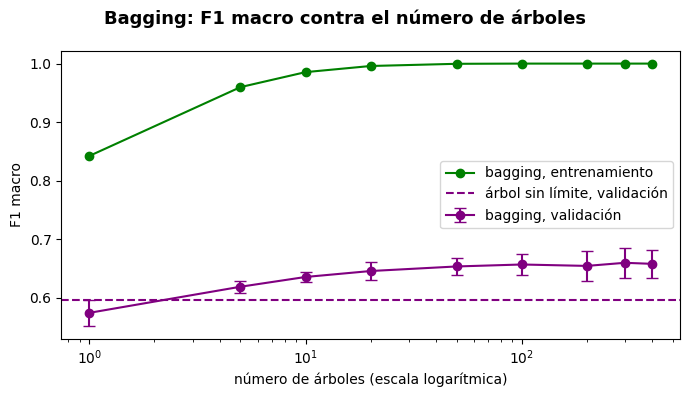

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(n_arboles, curva_bagging["entrenamiento"], color="green", marker="o", label="bagging, entrenamiento")
ax.errorbar(n_arboles, curva_bagging["validación"], yerr=curva_bagging["desv. est."],
            color="purple", marker="o", capsize=4, label="bagging, validación")
ax.axhline(resultados["árbol sin límite"]["F1 macro"], color="purple", linestyle="--", label="árbol sin límite, validación")
ax.set_xscale("log")
ax.set_xlabel("número de árboles (escala logarítmica)")
ax.set_ylabel("F1 macro")
ax.legend()
fig.suptitle("Bagging: F1 macro contra el número de árboles", fontsize=13, color="black", fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
bagging_400 = make_pipeline(prepara_arboles(),
                            BaggingClassifier(DecisionTreeClassifier(random_state=SEMILLA), n_estimators=400,
                                              random_state=SEMILLA))
resultados["bagging, 400 árboles"] = evaluar(bagging_400, X, y, pliegues, metricas)
modelos["bagging, 400 árboles"] = bagging_400
pd.DataFrame.from_dict(resultados, orient="index").loc[["árbol sin límite", "bagging, 400 árboles"]].round(3)

,F1 macro,desv. est.,sensibilidad,tiempo de entrenamiento (s)
árbol sin límite,0.596,0.010,0.380,0.277
"bagging, 400 árboles",0.658,0.024,0.313,29.622


El árbol sin límite logra 0.596 en validación. Bagging pasa de 0.574 con un árbol a 0.658 con 400, y desde unos 50 árboles se queda entre 0.653 y 0.659. En entrenamiento llega a 1.000.

Bagging reduce la varianza. Un árbol sin límite memoriza su muestra y cambia mucho de una muestra a otra. Al promediar árboles entrenados con muestras bootstrap distintas, esos errores se compensan en parte, mientras que el sesgo de cada árbol no cambia.

### Sesgo

Un tocón (árbol de profundidad 1) contra AdaBoost con 400 tocones. `staged_predict` da las predicciones del ensamble después de cada ronda.

In [ ]:
from sklearn.base import clone
from sklearn.ensemble import AdaBoostClassifier

tocon = make_pipeline(prepara_arboles(), DecisionTreeClassifier(max_depth=1, random_state=SEMILLA))
resultados["tocón"] = evaluar(tocon, X, y, pliegues, metricas)
modelos["tocón"] = tocon

adaboost = make_pipeline(prepara_arboles(),
                         AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=400,
                                            random_state=SEMILLA))
resultados["AdaBoost, 400 tocones"] = evaluar(adaboost, X, y, pliegues, metricas)
modelos["AdaBoost, 400 tocones"] = adaboost

curva_entrena, curva_valida = [], []
for entrena, valida in pliegues:
    ajustado = clone(adaboost).fit(X.iloc[entrena], y.iloc[entrena])
    prepara, ada = ajustado[:-1], ajustado[-1]
    curva_entrena.append([f1_score(y.iloc[entrena], p, average="macro")
                          for p in ada.staged_predict(prepara.transform(X.iloc[entrena]))])
    curva_valida.append([f1_score(y.iloc[valida], p, average="macro")
                         for p in ada.staged_predict(prepara.transform(X.iloc[valida]))])

rondas = min(len(c) for c in curva_valida)  # por si AdaBoost se detiene antes en algún pliegue
curva_ada = pd.DataFrame({"entrenamiento": np.mean([c[:rondas] for c in curva_entrena], axis=0),
                          "validación": np.mean([c[:rondas] for c in curva_valida], axis=0),
                          "desv. est.": np.std([c[:rondas] for c in curva_valida], axis=0)},
                         index=pd.RangeIndex(1, rondas + 1, name="ronda"))
print(f"Tocón, validación: {resultados['tocón']['F1 macro']:.3f} ± {resultados['tocón']['desv. est.']:.3f}")
curva_ada[curva_ada.index.isin([1, 10, 50, 100, 200, 300, 400])].round(3).T

Tocón, validación: 0.492 ± 0.012


ronda,1,10,50,100,200,300,400
entrenamiento,0.492,0.518,0.579,0.622,0.646,0.654,0.661
validación,0.492,0.516,0.574,0.607,0.630,0.634,0.641
desv. est.,0.012,0.015,0.018,0.017,0.010,0.006,0.007


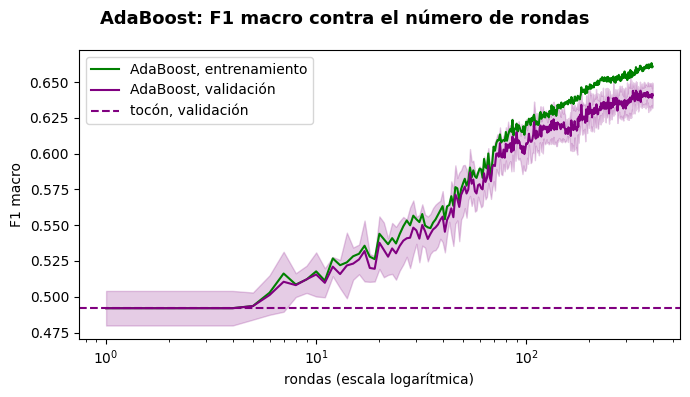

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curva_ada.index, curva_ada["entrenamiento"], color="green", label="AdaBoost, entrenamiento")
ax.plot(curva_ada.index, curva_ada["validación"], color="purple", label="AdaBoost, validación")
ax.fill_between(curva_ada.index, curva_ada["validación"] - curva_ada["desv. est."],
                curva_ada["validación"] + curva_ada["desv. est."], color="purple", alpha=0.2)
ax.axhline(resultados["tocón"]["F1 macro"], color="purple", linestyle="--", label="tocón, validación")
ax.set_xscale("log")
ax.set_xlabel("rondas (escala logarítmica)")
ax.set_ylabel("F1 macro")
ax.legend()
fig.suptitle("AdaBoost: F1 macro contra el número de rondas", fontsize=13, color="black", fontweight="bold")
plt.tight_layout()
plt.show()

El tocón solo logra 0.492 en validación. AdaBoost sube a 0.641 en validación y a 0.661 en entrenamiento después de 400 rondas, y la curva todavía no se aplana.

Boosting reduce el sesgo. Un tocón hace una sola pregunta y no alcanza a separar las tres clases; aquí nunca predice Enrolled (sensibilidad de 0). Cada ronda entrena un tocón nuevo con más peso en los estudiantes mal clasificados, y la suma ponderada de los tocones es un modelo más flexible que cualquiera de ellos.

### Combinar los cinco base

Votación dura, votación suave y stacking con meta-modelo logístico. La dura usa los cinco tal como quedaron. La suave y el stacking necesitan probabilidades, así que el SVM se envuelve en `CalibratedClassifierCV`. Como va dentro del ensamble, la calibración se ajusta solo con el entrenamiento de cada pliegue.

In [ ]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import StackingClassifier, VotingClassifier

cortes = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
con_probabilidades = {**base, "SVM": CalibratedClassifierCV(base["SVM"], ensemble=False, cv=cortes)}

combinados = {
    "votación dura": VotingClassifier(list(base.items()), voting="hard"),
    "votación suave": VotingClassifier(list(con_probabilidades.items()), voting="soft"),
    "stacking": StackingClassifier(list(con_probabilidades.items()),
                                   final_estimator=LogisticRegression(max_iter=5000), cv=cortes),
}
for nombre, modelo in combinados.items():
    resultados[nombre] = evaluar(modelo, X, y, pliegues, metricas)
    modelos[nombre] = modelo

pd.DataFrame.from_dict(resultados, orient="index").loc[list(base) + list(combinados)].round(3)

,F1 macro,desv. est.,sensibilidad,tiempo de entrenamiento (s)
árbol,0.639,0.013,0.457,0.176
Naive Bayes,0.619,0.012,0.351,0.131
kNN,0.568,0.013,0.214,0.246
SVM,0.688,0.006,0.608,3.192
regresión logística,0.682,0.008,0.576,9.517
votación dura,0.678,0.005,0.485,8.001
votación suave,0.674,0.006,0.403,14.881
stacking,0.667,0.013,0.350,69.998


Para ver qué tan parecidos son los errores de los cinco, se obtienen sus predicciones de validación cruzada con los mismos pliegues. Si los errores fueran independientes, el número esperado de estudiantes en que fallan los cinco sería el producto de sus tasas de error por el total.

In [ ]:
from sklearn.model_selection import cross_val_predict

errores = pd.DataFrame({nombre: cross_val_predict(modelo, X, y, cv=pliegues, n_jobs=-1) != y.to_numpy()
                        for nombre, modelo in base.items()})
correlacion = errores.astype(float).corr()

print(f"Fallan los cinco en {errores.all(axis=1).sum()} estudiantes; "
      f"si sus errores fueran independientes, serían {np.prod(errores.mean()) * len(errores):.1f}")
print(f"Aciertan los cinco en {(~errores).all(axis=1).sum()}; "
      f"si fueran independientes, serían {np.prod(1 - errores.mean()) * len(errores):.1f}")
print(f"Correlación media de los errores entre pares: {correlacion.to_numpy()[np.triu_indices(5, 1)].mean():.2f}")
correlacion.round(2)

Fallan los cinco en 448 estudiantes; si sus errores fueran independientes, serían 8.4
Aciertan los cinco en 1701; si fueran independientes, serían 597.0
Correlación media de los errores entre pares: 0.55


,árbol,Naive Bayes,kNN,SVM,regresión logística
árbol,1.00,0.56,0.47,0.60,0.59
Naive Bayes,0.56,1.00,0.52,0.55,0.56
kNN,0.47,0.52,1.00,0.43,0.42
SVM,0.60,0.55,0.43,1.00,0.81
regresión logística,0.59,0.56,0.42,0.81,1.00


La correlación media entre los errores es 0.55, y la más alta es la del SVM con la logística (0.81). Los cinco fallan juntos en 448 estudiantes, contra 8.4 esperados si fueran independientes.

Cuando los errores están correlacionados, combinar aporta poco, porque si un modelo falla los demás suelen fallar con él y no hay votos que corrijan. La votación dura, la suave y el stacking quedan en 0.678, 0.674 y 0.667, contra 0.688 del SVM, el mejor de los cinco.

### Bagging optimizado

`buscar` corre `RandomizedSearchCV` con los mismos pliegues y guarda la mejor configuración con sus métricas. Como en la Práctica 3, la gráfica de meseta va contra el hiperparámetro más influyente, el de mayor diferencia entre el mejor F1 macro de su mejor valor y el de su peor valor.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV


def buscar(modelo, espacio, X, y, cv, metricas, n_iter):
    inicio = time.perf_counter()
    busqueda = RandomizedSearchCV(modelo, espacio, n_iter=n_iter, cv=cv, scoring=metricas, refit="f1_macro",
                                  random_state=SEMILLA, n_jobs=-1).fit(X, y)
    r, i = busqueda.cv_results_, busqueda.best_index_
    fila = {"F1 macro": r["mean_test_f1_macro"][i], "desv. est.": r["std_test_f1_macro"][i],
            "sensibilidad": r["mean_test_sensibilidad"][i], "tiempo de entrenamiento (s)": r["mean_fit_time"][i],
            "tiempo de búsqueda (s)": time.perf_counter() - inicio,
            "mejor configuración": {k.split("__")[-1]: v for k, v in busqueda.best_params_.items()}}
    return busqueda, fila


def influencia(busqueda):
    resultados_b = pd.DataFrame(busqueda.cv_results_)
    diferencias = {}
    for col in [c for c in resultados_b.columns if c.startswith("param_")]:
        mejor_por_valor = resultados_b.groupby(resultados_b[col].map(str))["mean_test_f1_macro"].max()
        diferencias[col] = mejor_por_valor.max() - mejor_por_valor.min()
    return pd.Series(diferencias, name="diferencia en F1 macro").sort_values(ascending=False)


def meseta(busqueda, titulo):
    resultados_b = pd.DataFrame(busqueda.cv_results_)
    param = influencia(busqueda).index[0]
    nombre = param.split("__")[-1]
    indices = resultados_b.groupby(resultados_b[param].map(str))["mean_test_f1_macro"].idxmax()
    mejores = resultados_b.loc[indices]
    mejores = mejores.assign(orden=pd.to_numeric(mejores[param], errors="coerce")).sort_values("orden", na_position="first")

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.errorbar(mejores[param].map(str), mejores["mean_test_f1_macro"], yerr=mejores["std_test_f1_macro"],
                color="purple", marker="o", capsize=4)
    ax.set_xlabel(nombre)
    ax.set_ylabel("F1 macro de validación")
    fig.suptitle(f"{titulo}: F1 macro contra {nombre}", fontsize=13, color="black", fontweight="bold")
    plt.tight_layout()
    plt.show()

Random Forest y Extra-Trees, 50 configuraciones cada uno. Se buscan `max_features`, el tamaño mínimo de las hojas, el criterio, los pesos por clase y, en Extra-Trees, `bootstrap`. Los dos usan 400 árboles, el mayor número de la curva de varianza.

In [ ]:
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier

espacio_rf = {
    "randomforestclassifier__max_features": ["sqrt", "log2", 0.1, 0.2, 0.3],
    "randomforestclassifier__min_samples_leaf": [1, 2, 3, 5, 10, 20],
    "randomforestclassifier__criterion": ["gini", "entropy"],
    "randomforestclassifier__class_weight": [None, "balanced", "balanced_subsample"],
}
busqueda_rf, resultados["Random Forest"] = buscar(
    make_pipeline(prepara_arboles(), RandomForestClassifier(n_estimators=400, random_state=SEMILLA)),
    espacio_rf, X, y, pliegues, metricas, n_iter=50)
modelos["Random Forest"] = busqueda_rf.best_estimator_
pd.Series(resultados["Random Forest"])

,0
F1 macro,0.68064
desv. est.,0.014294
sensibilidad,0.483465
tiempo de entrenamiento (s),10.716388
tiempo de búsqueda (s),850.203916
mejor configuración,"{'min_samples_leaf': 5, 'max_features': 0.3, '..."


In [ ]:
influencia(busqueda_rf).rename(lambda c: c.split("__")[-1]).round(3)

,diferencia en F1 macro
max_features,0.048
min_samples_leaf,0.027
class_weight,0.027
criterion,0.003


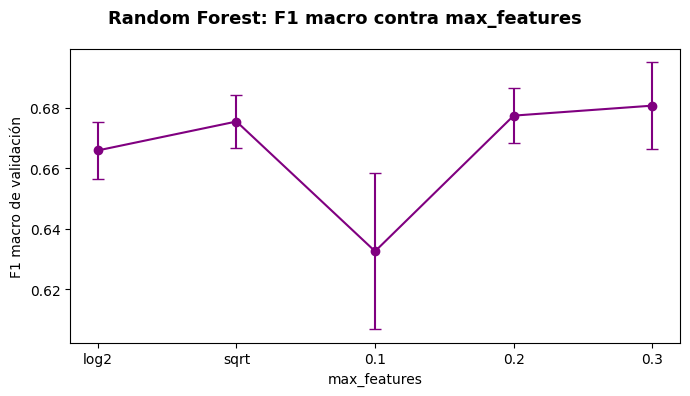

In [ ]:
meseta(busqueda_rf, "Random Forest")

In [ ]:
espacio_et = {
    "extratreesclassifier__max_features": ["sqrt", "log2", 0.1, 0.2, 0.3],
    "extratreesclassifier__min_samples_leaf": [1, 2, 3, 5, 10, 20],
    "extratreesclassifier__criterion": ["gini", "entropy"],
    "extratreesclassifier__class_weight": [None, "balanced", "balanced_subsample"],
    "extratreesclassifier__bootstrap": [False, True],
}
busqueda_et, resultados["Extra-Trees"] = buscar(
    make_pipeline(prepara_arboles(), ExtraTreesClassifier(n_estimators=400, random_state=SEMILLA)),
    espacio_et, X, y, pliegues, metricas, n_iter=50)
modelos["Extra-Trees"] = busqueda_et.best_estimator_
pd.Series(resultados["Extra-Trees"])

,0
F1 macro,0.66806
desv. est.,0.011853
sensibilidad,0.404724
tiempo de entrenamiento (s),8.503987
tiempo de búsqueda (s),842.922415
mejor configuración,"{'min_samples_leaf': 3, 'max_features': 0.3, '..."


In [ ]:
influencia(busqueda_et).rename(lambda c: c.split("__")[-1]).round(3)

,diferencia en F1 macro
class_weight,0.032
max_features,0.031
min_samples_leaf,0.026
criterion,0.000
bootstrap,0.000


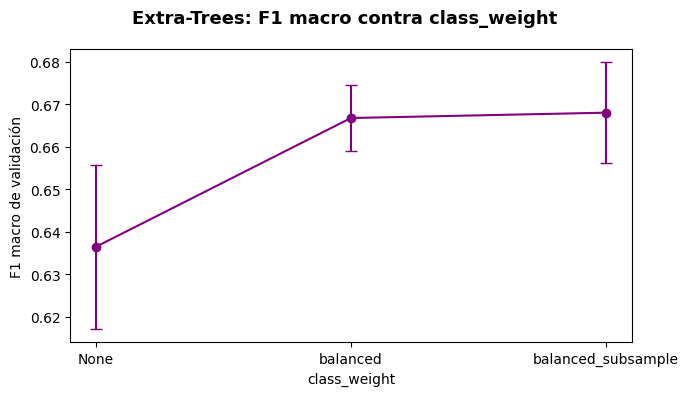

In [ ]:
meseta(busqueda_et, "Extra-Trees")

### Boosting optimizado

LightGBM y CatBoost, 50 configuraciones cada uno. Se buscan el número de rondas, la tasa de aprendizaje, el tamaño de los árboles (hojas en LightGBM, profundidad en CatBoost), la regularización L2 de las hojas, el submuestreo de filas y de columnas, y los pesos por clase. En LightGBM el submuestreo de filas solo se activa con `subsample_freq=1`, y en CatBoost con `bootstrap_type="Bernoulli"`. Cada modelo usa un solo hilo para no competir con la búsqueda en paralelo.

En CatBoost, el espacio se parte en dos, uno sin pesos (valor por omisión) y otro con `"Balanced"`, porque la búsqueda no puede pasarle `auto_class_weights=None`. En la influencia y la meseta, la opción sin pesos aparece como `nan`.

In [ ]:
from lightgbm import LGBMClassifier

espacio_lgbm = {
    "lgbmclassifier__n_estimators": [100, 200, 400, 800],
    "lgbmclassifier__learning_rate": [0.01, 0.03, 0.1, 0.3],
    "lgbmclassifier__num_leaves": [7, 15, 31, 63],
    "lgbmclassifier__reg_lambda": [0, 0.1, 1, 10],
    "lgbmclassifier__subsample": [0.6, 0.8, 1.0],
    "lgbmclassifier__subsample_freq": [1],
    "lgbmclassifier__colsample_bytree": [0.3, 0.6, 1.0],
    "lgbmclassifier__class_weight": [None, "balanced"],
}
busqueda_lgbm, resultados["LightGBM"] = buscar(
    make_pipeline(prepara_arboles(), LGBMClassifier(random_state=SEMILLA, verbose=-1, n_jobs=1)),
    espacio_lgbm, X, y, pliegues, metricas, n_iter=50)
modelos["LightGBM"] = busqueda_lgbm.best_estimator_
pd.Series(resultados["LightGBM"])

,0
F1 macro,0.689449
desv. est.,0.015511
sensibilidad,0.584252
tiempo de entrenamiento (s),3.958009
tiempo de búsqueda (s),350.06609
mejor configuración,"{'subsample_freq': 1, 'subsample': 1.0, 'reg_l..."


In [ ]:
influencia(busqueda_lgbm).rename(lambda c: c.split("__")[-1]).round(3)

,diferencia en F1 macro
learning_rate,0.022
class_weight,0.021
colsample_bytree,0.017
num_leaves,0.011
n_estimators,0.010
subsample,0.007
reg_lambda,0.007
subsample_freq,0.000


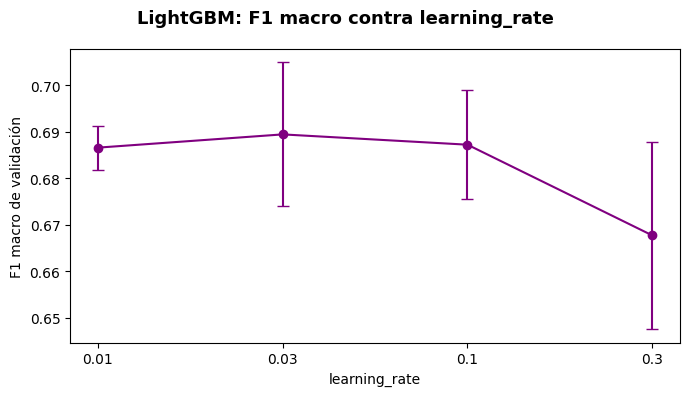

In [ ]:
meseta(busqueda_lgbm, "LightGBM")

In [ ]:
from catboost import CatBoostClassifier

espacio_cat_comun = {
    "catboostclassifier__iterations": [200, 400, 800],
    "catboostclassifier__learning_rate": [0.03, 0.1, 0.3],
    "catboostclassifier__depth": [4, 6, 8],
    "catboostclassifier__l2_leaf_reg": [1, 3, 10, 30],
    "catboostclassifier__bootstrap_type": ["Bernoulli"],
    "catboostclassifier__subsample": [0.6, 0.8, 1.0],
    "catboostclassifier__rsm": [0.3, 0.6, 1.0],
}
# Sin pesos se deja el valor por omisión; CatBoost no acepta auto_class_weights=None en la búsqueda
espacio_cat = [espacio_cat_comun, {**espacio_cat_comun, "catboostclassifier__auto_class_weights": ["Balanced"]}]
busqueda_cat, resultados["CatBoost"] = buscar(
    make_pipeline(prepara_arboles(), CatBoostClassifier(random_seed=SEMILLA, verbose=0, allow_writing_files=False,
                                                        thread_count=1)),
    espacio_cat, X, y, pliegues, metricas, n_iter=50)
modelos["CatBoost"] = busqueda_cat.best_estimator_
pd.Series(resultados["CatBoost"])

,0
F1 macro,0.691708
desv. est.,0.012885
sensibilidad,0.548031
tiempo de entrenamiento (s),4.503696
tiempo de búsqueda (s),1060.888637
mejor configuración,"{'subsample': 1.0, 'rsm': 0.3, 'learning_rate'..."


In [ ]:
influencia(busqueda_cat).rename(lambda c: c.split("__")[-1]).round(3)

,diferencia en F1 macro
auto_class_weights,0.026
learning_rate,0.008
depth,0.007
l2_leaf_reg,0.007
iterations,0.004
subsample,0.004
rsm,0.004
bootstrap_type,0.000


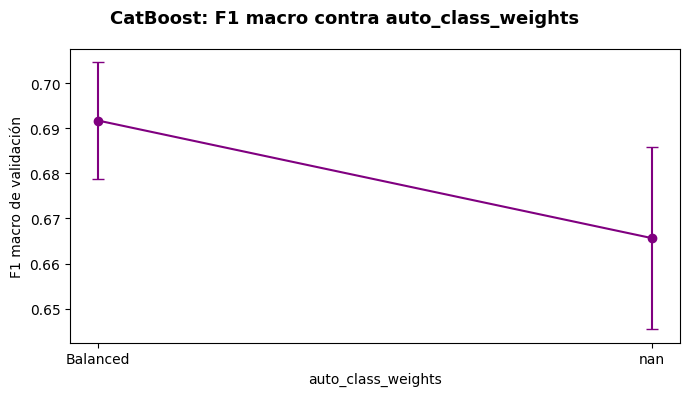

In [ ]:
meseta(busqueda_cat, "CatBoost")

### Todos los modelos

Ordenados por F1 macro (media y desviación entre pliegues). La sensibilidad de `Enrolled` y el tiempo de entrenamiento son promedios por pliegue. En los optimizados se agregan el tiempo de la búsqueda completa y la mejor configuración.

In [ ]:
pd.set_option("display.max_colwidth", None)
tabla_desercion = (pd.DataFrame.from_dict(resultados, orient="index")
                   .rename(columns={"sensibilidad": "sens. Enrolled"})
                   .sort_values("F1 macro", ascending=False))
tabla_desercion.round(3)

,F1 macro,desv. est.,sens. Enrolled,tiempo de entrenamiento (s),tiempo de búsqueda (s),mejor configuración
CatBoost,0.692,0.013,0.548,4.504,1060.889,"{'subsample': 1.0, 'rsm': 0.3, 'learning_rate': 0.1, 'l2_leaf_reg': 3, 'iterations': 400, 'depth': 6, 'bootstrap_type': 'Bernoulli', 'auto_class_weights': 'Balanced'}"
LightGBM,0.689,0.016,0.584,3.958,350.066,"{'subsample_freq': 1, 'subsample': 1.0, 'reg_lambda': 10, 'num_leaves': 7, 'n_estimators': 800, 'learning_rate': 0.03, 'colsample_bytree': 0.3, 'class_weight': 'balanced'}"
SVM,0.688,0.006,0.608,3.192,NaN,NaN
regresión logística,0.682,0.008,0.576,9.517,NaN,NaN
Random Forest,0.681,0.014,0.483,10.716,850.204,"{'min_samples_leaf': 5, 'max_features': 0.3, 'criterion': 'entropy', 'class_weight': 'balanced'}"
votación dura,0.678,0.005,0.485,8.001,NaN,NaN
votación suave,0.674,0.006,0.403,14.881,NaN,NaN
Extra-Trees,0.668,0.012,0.405,8.504,842.922,"{'min_samples_leaf': 3, 'max_features': 0.3, 'criterion': 'entropy', 'class_weight': 'balanced_subsample', 'bootstrap': True}"
stacking,0.667,0.013,0.350,69.998,NaN,NaN
"bagging, 400 árboles",0.658,0.024,0.313,29.622,NaN,NaN


Matriz de confusión del mejor modelo, con sus predicciones de validación cruzada.

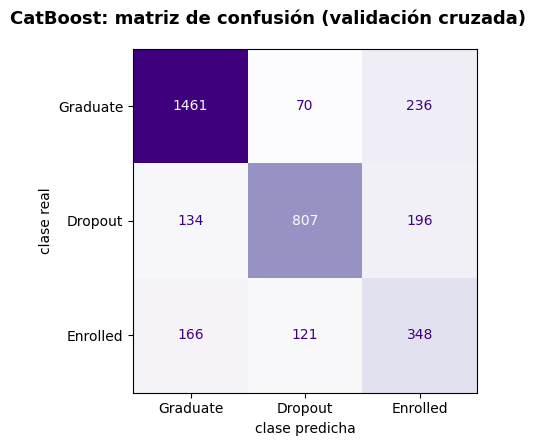

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

mejor = tabla_desercion.index[0]
pred_mejor = cross_val_predict(modelos[mejor], X, y, cv=pliegues, n_jobs=-1)

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y, pred_mejor, labels=CLASES), display_labels=CLASES).plot(
    ax=ax, cmap="Purples", colorbar=False)
ax.set_xlabel("clase predicha")
ax.set_ylabel("clase real")
fig.suptitle(f"{mejor}: matriz de confusión (validación cruzada)", fontsize=13, color="black", fontweight="bold")
plt.tight_layout()
plt.show()

El mejor es CatBoost, con F1 macro de 0.692 ± 0.013, contra 0.688 del SVM, el mejor de la Práctica 3. La diferencia es menor que la desviación entre pliegues, así que en la práctica empatan, y el SVM detecta más Enrolled (0.608 contra 0.548). En la matriz, Enrolled sigue siendo la clase difícil, con 348 aciertos de 635; los demás se van a Graduate (166) y a Dropout (121).

## BANK MARKETING

El archivo `bank-additional-full.csv` de UCI (dataset 222). Si no está en la carpeta `datos/`, se descarga del zip de UCI, que trae adentro otro zip con el archivo.

In [ ]:
ruta_bank = "datos/bank-additional-full.csv"
if not os.path.exists(ruta_bank):
    os.makedirs("datos", exist_ok=True)
    url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
    with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())) as externo:
        nombre_zip = [n for n in externo.namelist() if n.endswith("bank-additional.zip")][0]
        with zipfile.ZipFile(io.BytesIO(externo.read(nombre_zip))) as interno:
            nombre_csv = [n for n in interno.namelist()
                          if n.endswith("bank-additional-full.csv") and not n.startswith("__MACOSX")][0]
            with open(ruta_bank, "wb") as archivo:
                archivo.write(interno.read(nombre_csv))

df_bank = pd.read_csv(ruta_bank, sep=";")
df_bank.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Revisión general

Dimensiones, tipo de dato, faltantes, duplicados y distribución de las clases.

In [ ]:
pd.Series({
    "registros": df_bank.shape[0],
    "columnas": df_bank.shape[1],
    "numéricas": df_bank.select_dtypes(include="number").shape[1],
    "no numéricas": df_bank.select_dtypes(exclude="number").shape[1],
    "registros con faltantes": df_bank.isna().any(axis=1).sum(),
    "duplicados exactos": df_bank.duplicated().sum(),
}, name="Bank Marketing")

,Bank Marketing
registros,41188
columnas,21
numéricas,10
no numéricas,11
registros con faltantes,0
duplicados exactos,12


In [ ]:
df_bank["y"].value_counts().to_frame("clientes").assign(
    proporción=lambda t: (t["clientes"] / len(df_bank)).round(3))

,clientes,proporción
y,,
no,36548,0.887
yes,4640,0.113


Por la consigna, X es el archivo completo sin `duration` ni `y`, así que no se elimina ninguna fila. La clase se codifica como 1 (yes) y 0 (no), y los pliegues son los de la consigna. Las columnas se separan por tipo de dato para el preprocesamiento.

In [ ]:
X_bank = df_bank.drop(columns=["duration", "y"])
y_bank = (df_bank["y"] == "yes").astype(int)

categoricas_bank = X_bank.select_dtypes(exclude="number").columns.tolist()
numericas_bank = X_bank.select_dtypes(include="number").columns.tolist()

cv_bank = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
metricas_bank = {"f1_macro": "f1_macro", "sensibilidad": "recall"}  # recall de la clase 1 (yes)

print(f"Categóricas ({len(categoricas_bank)}): {categoricas_bank}")
print(f"Numéricas ({len(numericas_bank)}): {numericas_bank}")

Categóricas (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numéricas (9): ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


### Preprocesamiento

Las categóricas van en one-hot y las numéricas se estandarizan, todo dentro del pipeline para que se ajuste solo con los pliegues de entrenamiento. Una categoría que no aparezca en el entrenamiento de un pliegue recibe ceros. Naive Bayes usa el preprocesamiento discretizado de la deserción.

In [ ]:
def prepara_bank():
    return ColumnTransformer([
        ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas_bank),
        ("numericas", StandardScaler(), numericas_bank)])


desconocida_bank = X_bank[categoricas_bank].nunique().max()  # código para categorías no vistas
nb_bank = Pipeline([
    ("prepara", ColumnTransformer([
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=desconocida_bank,
                                       dtype=int), categoricas_bank),
        ("numericas", KBinsDiscretizer(n_bins=10, encode="ordinal", strategy="quantile"), numericas_bank)])),
    ("nb", CategoricalNB(min_categories=desconocida_bank + 1))])

### Línea base y cribado

Cada clasificador y cada ensamble con sus valores por omisión, para elegir cuáles optimizar. El SVM con kernel RBF queda fuera, porque su entrenamiento crece aproximadamente con el cuadrado del número de ejemplos y con unos 33 mil por pliegue cada ajuste tardaría demasiado.

In [ ]:
from sklearn.dummy import DummyClassifier

cribado = {
    "línea base": DummyClassifier(strategy="most_frequent"),
    "árbol": make_pipeline(prepara_bank(), DecisionTreeClassifier(random_state=SEMILLA)),
    "Naive Bayes": nb_bank,
    "kNN": make_pipeline(prepara_bank(), KNeighborsClassifier()),
    "regresión logística": make_pipeline(prepara_bank(), LogisticRegression(max_iter=5000, random_state=SEMILLA)),
    "bagging": make_pipeline(prepara_bank(), BaggingClassifier(DecisionTreeClassifier(random_state=SEMILLA),
                                                               random_state=SEMILLA)),
    "Random Forest": make_pipeline(prepara_bank(), RandomForestClassifier(random_state=SEMILLA)),
    "Extra-Trees": make_pipeline(prepara_bank(), ExtraTreesClassifier(random_state=SEMILLA)),
    "AdaBoost": make_pipeline(prepara_bank(), AdaBoostClassifier(random_state=SEMILLA)),
    "LightGBM": make_pipeline(prepara_bank(), LGBMClassifier(random_state=SEMILLA, verbose=-1, n_jobs=1)),
    "CatBoost": make_pipeline(prepara_bank(), CatBoostClassifier(random_seed=SEMILLA, verbose=0,
                                                                 allow_writing_files=False, thread_count=1)),
}

resultados_bank = {}
modelos_bank = {}
for nombre, modelo in cribado.items():
    resultados_bank[nombre] = evaluar(modelo, X_bank, y_bank, cv_bank, metricas_bank)
    modelos_bank[nombre] = modelo

pd.DataFrame.from_dict(resultados_bank, orient="index").sort_values("F1 macro", ascending=False).round(3)

,F1 macro,desv. est.,sensibilidad,tiempo de entrenamiento (s)
Naive Bayes,0.686,0.007,0.598,0.446
LightGBM,0.664,0.006,0.270,0.914
Random Forest,0.662,0.006,0.295,8.466
CatBoost,0.662,0.011,0.273,23.139
kNN,0.660,0.011,0.294,0.271
Extra-Trees,0.653,0.009,0.309,10.826
bagging,0.649,0.007,0.280,4.670
regresión logística,0.642,0.010,0.228,0.741
AdaBoost,0.631,0.011,0.205,4.405
árbol,0.622,0.008,0.347,0.980


### Optimización

Se optimizan los dos con mayor F1 macro del cribado, con `RandomizedSearchCV` de 20 configuraciones y los mismos pliegues. Cada espacio incluye los pesos por clase cuando el modelo los admite.

In [ ]:
espacios_bank = {
    "árbol": {"decisiontreeclassifier__max_depth": [3, 5, 8, 12, None],
              "decisiontreeclassifier__min_samples_leaf": [1, 5, 20, 50, 100],
              "decisiontreeclassifier__criterion": ["gini", "entropy"],
              "decisiontreeclassifier__class_weight": [None, "balanced"]},
    "Naive Bayes": {"prepara__numericas__n_bins": [3, 5, 8, 10, 15],
                    "nb__alpha": [0.1, 0.3, 1, 3, 10]},
    "kNN": {"kneighborsclassifier__n_neighbors": [5, 11, 21, 51, 101],
            "kneighborsclassifier__weights": ["uniform", "distance"],
            "kneighborsclassifier__p": [1, 2]},
    "regresión logística": {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10],
                            "logisticregression__class_weight": [None, "balanced"]},
    "bagging": {"baggingclassifier__n_estimators": [50, 100, 200],
                "baggingclassifier__max_samples": [0.3, 0.6, 1.0],
                "baggingclassifier__max_features": [0.3, 0.6, 1.0],
                "baggingclassifier__estimator__min_samples_leaf": [1, 5, 20],
                "baggingclassifier__estimator__class_weight": [None, "balanced"]},
    "Random Forest": {"randomforestclassifier__n_estimators": [100, 200],
                      "randomforestclassifier__max_features": ["sqrt", "log2", 0.3, 0.5],
                      "randomforestclassifier__min_samples_leaf": [1, 5, 20, 50],
                      "randomforestclassifier__criterion": ["gini", "entropy"],
                      "randomforestclassifier__class_weight": [None, "balanced", "balanced_subsample"]},
    "Extra-Trees": {"extratreesclassifier__n_estimators": [100, 200],
                    "extratreesclassifier__max_features": ["sqrt", "log2", 0.3, 0.5],
                    "extratreesclassifier__min_samples_leaf": [1, 5, 20, 50],
                    "extratreesclassifier__criterion": ["gini", "entropy"],
                    "extratreesclassifier__class_weight": [None, "balanced", "balanced_subsample"],
                    "extratreesclassifier__bootstrap": [False, True]},
    "AdaBoost": {"adaboostclassifier__n_estimators": [100, 200, 400],
                 "adaboostclassifier__learning_rate": [0.1, 0.3, 1],
                 "adaboostclassifier__estimator": [DecisionTreeClassifier(max_depth=d) for d in [1, 2, 3]]},
    "LightGBM": espacio_lgbm,
    "CatBoost": espacio_cat,
}

cribado_ordenado = (pd.DataFrame.from_dict(resultados_bank, orient="index").drop("línea base")["F1 macro"]
                    .sort_values(ascending=False))
elegidos = cribado_ordenado.index[:2].tolist()
print("Se optimizan:", elegidos)

busquedas_bank = {}
for nombre in elegidos:
    busquedas_bank[nombre], resultados_bank[f"{nombre} optimizado"] = buscar(
        cribado[nombre], espacios_bank[nombre], X_bank, y_bank, cv_bank, metricas_bank, n_iter=20)
    modelos_bank[f"{nombre} optimizado"] = busquedas_bank[nombre].best_estimator_

pd.DataFrame.from_dict(resultados_bank, orient="index").loc[[f"{n} optimizado" for n in elegidos]].round(3)

Se optimizan: ['Naive Bayes', 'LightGBM']


,F1 macro,desv. est.,sensibilidad,tiempo de entrenamiento (s),tiempo de búsqueda (s),mejor configuración
Naive Bayes optimizado,0.693,0.008,0.591,0.249,24.304,"{'n_bins': 5, 'alpha': 10}"
LightGBM optimizado,0.697,0.005,0.633,2.663,183.541,"{'subsample_freq': 1, 'subsample': 0.6, 'reg_lambda': 0.1, 'num_leaves': 63, 'n_estimators': 200, 'learning_rate': 0.01, 'colsample_bytree': 0.3, 'class_weight': 'balanced'}"


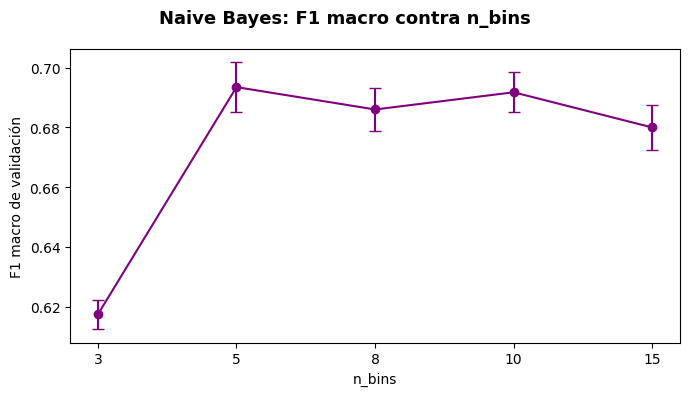

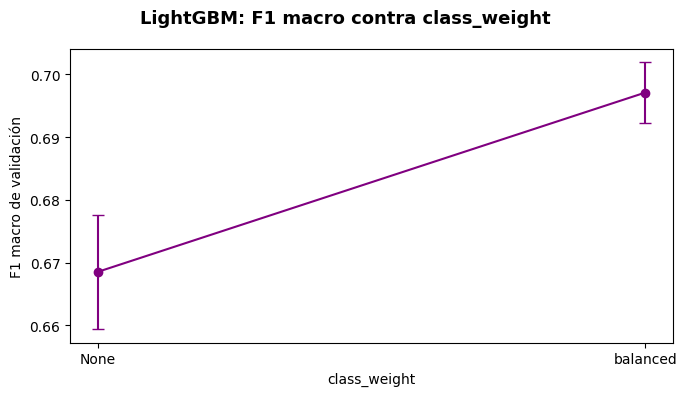

In [ ]:
for nombre in elegidos:
    meseta(busquedas_bank[nombre], nombre)

### Ensamble y umbral

Votación suave de los dos optimizados. Después, el umbral. `predict` usa 0.5, pero ese umbral no tiene por qué ser el que da el mejor F1 macro (notebook 11). `TunedThresholdClassifierCV` lo elige con validación cruzada dentro del entrenamiento de cada pliegue, y se aplica al mejor modelo hasta aquí.

In [ ]:
votacion_bank = VotingClassifier([(nombre, busquedas_bank[nombre].best_estimator_) for nombre in elegidos],
                                 voting="soft")
resultados_bank["votación suave"] = evaluar(votacion_bank, X_bank, y_bank, cv_bank, metricas_bank)
modelos_bank["votación suave"] = votacion_bank
pd.Series(resultados_bank["votación suave"])

,0
F1 macro,0.696688
desv. est.,0.007259
sensibilidad,0.599569
tiempo de entrenamiento (s),3.374858


In [ ]:
from sklearn.model_selection import TunedThresholdClassifierCV

candidatos = [f"{nombre} optimizado" for nombre in elegidos] + ["votación suave"]
mejor_hasta_aqui = max(candidatos, key=lambda n: resultados_bank[n]["F1 macro"])

con_umbral = TunedThresholdClassifierCV(modelos_bank[mejor_hasta_aqui], scoring="f1_macro",
                                        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=2026))
resultados_bank[f"{mejor_hasta_aqui}, umbral ajustado"] = evaluar(con_umbral, X_bank, y_bank, cv_bank, metricas_bank)
modelos_bank[f"{mejor_hasta_aqui}, umbral ajustado"] = con_umbral
print("Umbral ajustado sobre:", mejor_hasta_aqui)
pd.DataFrame.from_dict(resultados_bank, orient="index").loc[[mejor_hasta_aqui, f"{mejor_hasta_aqui}, umbral ajustado"]].round(3)

Umbral ajustado sobre: LightGBM optimizado


,F1 macro,desv. est.,sensibilidad,tiempo de entrenamiento (s),tiempo de búsqueda (s),mejor configuración
LightGBM optimizado,0.697,0.005,0.633,2.663,183.541,"{'subsample_freq': 1, 'subsample': 0.6, 'reg_lambda': 0.1, 'num_leaves': 63, 'n_estimators': 200, 'learning_rate': 0.01, 'colsample_bytree': 0.3, 'class_weight': 'balanced'}"
"LightGBM optimizado, umbral ajustado",0.716,0.006,0.559,20.167,NaN,NaN


### Todos los modelos

Ordenados por F1 macro (media y desviación entre pliegues), con la sensibilidad de la clase yes y el tiempo de entrenamiento promedio por pliegue.

In [ ]:
tabla_bank = (pd.DataFrame.from_dict(resultados_bank, orient="index")
              .rename(columns={"sensibilidad": "sens. yes"})
              .sort_values("F1 macro", ascending=False))
tabla_bank.round(3)

,F1 macro,desv. est.,sens. yes,tiempo de entrenamiento (s),tiempo de búsqueda (s),mejor configuración
"LightGBM optimizado, umbral ajustado",0.716,0.006,0.559,20.167,NaN,NaN
LightGBM optimizado,0.697,0.005,0.633,2.663,183.541,"{'subsample_freq': 1, 'subsample': 0.6, 'reg_lambda': 0.1, 'num_leaves': 63, 'n_estimators': 200, 'learning_rate': 0.01, 'colsample_bytree': 0.3, 'class_weight': 'balanced'}"
votación suave,0.697,0.007,0.600,3.375,NaN,NaN
Naive Bayes optimizado,0.693,0.008,0.591,0.249,24.304,"{'n_bins': 5, 'alpha': 10}"
Naive Bayes,0.686,0.007,0.598,0.446,NaN,NaN
LightGBM,0.664,0.006,0.270,0.914,NaN,NaN
Random Forest,0.662,0.006,0.295,8.466,NaN,NaN
CatBoost,0.662,0.011,0.273,23.139,NaN,NaN
kNN,0.660,0.011,0.294,0.271,NaN,NaN
Extra-Trees,0.653,0.009,0.309,10.826,NaN,NaN


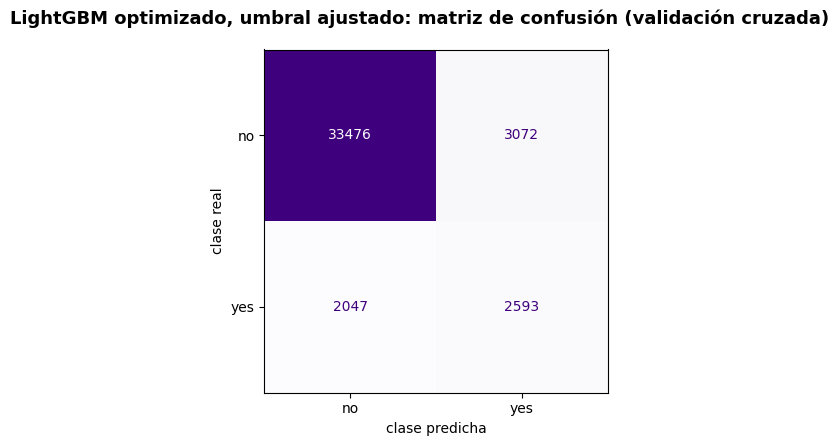

In [ ]:
mejor_bank = tabla_bank.index[0]
pred_bank = cross_val_predict(modelos_bank[mejor_bank], X_bank, y_bank, cv=cv_bank, n_jobs=-1)

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_bank, pred_bank), display_labels=["no", "yes"]).plot(
    ax=ax, cmap="Purples", colorbar=False)
ax.set_xlabel("clase predicha")
ax.set_ylabel("clase real")
fig.suptitle(f"{mejor_bank}: matriz de confusión (validación cruzada)", fontsize=13, color="black", fontweight="bold")
plt.tight_layout()
plt.show()

El mejor es LightGBM optimizado con umbral ajustado, con F1 macro de 0.716 ± 0.006 y sensibilidad de yes de 0.559. Ajustar el umbral subió el F1 macro de 0.697 a 0.716, a cambio de bajar la sensibilidad de yes de 0.633 a 0.559. De los 4,640 clientes que sí contrataron detecta 2,593, y marca como yes a 3,072 que no contrataron.

¿Funcionó lo mismo que en la deserción? En parte. En los dos problemas el mejor fue un boosting, pero por poco frente al mejor modelo sencillo. En la deserción CatBoost apenas supera al SVM, y en Bank LightGBM optimizado (0.697) queda junto a Naive Bayes optimizado (0.693) y a su votación suave (0.697).

La diferencia fue el peso del desbalance. En Bank, con valores por omisión, los ensambles detectan menos de un tercio de los yes (sensibilidad de 0.27 a 0.31) y quedan debajo de Naive Bayes. Los pesos por clase suben a LightGBM de 0.669 a 0.697, y el umbral lo lleva a 0.716. En la deserción los pesos por clase también ayudaron, pero ahí no se ajustó umbral y la clase minoritaria no es tan pequeña.

### Modelo final

El mejor modelo se reentrena con los 41,188 clientes y se guarda con joblib.

In [ ]:
modelo_final = clone(modelos_bank[mejor_bank]).fit(X_bank, y_bank)
nombre_modelo = mejor_bank.lower().replace(", ", "_").replace(" ", "_")
archivo_modelo = f"Heber_Zapata-{nombre_modelo}.joblib"
joblib.dump(modelo_final, archivo_modelo)
print("Guardado:", archivo_modelo)

Guardado: Heber_Zapata-lightgbm_optimizado_umbral_ajustado.joblib


## CONCLUSIONES

En la deserción, bagging redujo la varianza del árbol sin límite (de 0.596 a 0.658) y boosting el sesgo del tocón (de 0.492 a 0.641), pero en su forma simple ninguno alcanzó a los mejores base. Optimizados, CatBoost (0.692) y LightGBM (0.689) apenas superan al SVM (0.688), y Random Forest y Extra-Trees quedan debajo. Combinar los cinco base no ayudó (de 0.667 a 0.678), porque sus errores están muy correlacionados. En Bank Marketing, los ensambles con valores por omisión quedaron debajo de Naive Bayes, y LightGBM solo ganó con pesos por clase y umbral ajustado (0.716).

La diferencia principal está en de dónde vino la ganancia. En la deserción, los ensambles agregaron poco sobre modelos que ya estaban ajustados. En Bank, la ganancia vino más de atender el desbalance que del tipo de ensamble.

Los conjuntos difieren en tamaño (3,539 contra 41,188 registros), en número de clases (tres contra dos), en el tipo de atributos (8 nominales, 8 binarios, 1 ordinal y 12 numéricos en la deserción; 10 categóricas y 9 numéricas en Bank) y en el balance de clases (Enrolled es el 17.9 % de la deserción y yes el 11.3 % de Bank). Con una clase minoritaria más pequeña, un modelo sin pesos tiende a predecir la mayoritaria, y eso explica por qué los pesos por clase y el umbral pesaron más en Bank.

## DECLARACIÓN DE USO DE IA

Este notebook se elaboró con apoyo de Claude (Anthropic) para estructurar el código y la redacción. Las decisiones de análisis, la ejecución y la revisión de los resultados son responsabilidad del autor.